# GCI World Final Assignment: Telecommunications Customer Churn & Retention Optimization
### Matsuo-Iwasawa Laboratory | The University of Tokyo
**Author / Role:** Lead Data Scientist, Machine Learning Engineer & IT Strategy Consultant (New Associate)  
**Client:** Company A (Anonymous Telecommunications Service Provider)  
**Deliverable:** End-to-End Proof of Concept (PoC) — Data Integrity Verification, Defensible EDA, Leak-Free Machine Learning Pipeline, Decile Targeting, Quantified Financial Impact Scenarios, and Randomized Pilot Proposal.

---
### Executive Summary & Methodological Principles:
1. **Target Variable Definition:** As specified in Company A's dataset documentation, `churn` represents **churn occurring between 31 and 60 days after the observation date**. It is a 30-day target window outcome, **not an annualized churn rate**.
2. **Account Population vs. Active Subscribers:** The dataset comprises **100,000 customer account records** with an observed churn rate of **49.56%** (49,562 accounts churned) in the 31–60 day observation window. Active subscribers per account (`actvsubs`) range from 0 to 11 (mean 1.36); 81 accounts have 0 active subscribers.
3. **Data Availability & Leakage Boundaries:**
   - **Preprocessing Leakage:** Strictly prevented by fitting all learned transformers (imputers, encoders, scalers) **exclusively on the training partition** after an 80/20 stratified split. Target and customer IDs are excluded from the feature matrix.
   - **Data-Availability Timing:** Feature availability at the observation date is an **assumption** based on column descriptions and standard telecom churn modeling architectures (Month 0 observation, Month 1 retention campaign, Month 2 churn window). Because the dataset overview does not provide timestamps or billing cutoffs, timing availability must be confirmed with Company A prior to production deployment.
4. **Analytical Rigor & Language:** All empirical relationships between customer characteristics (e.g., equipment age `eqpdays`, usage decline `change_mou`, refurbished handsets `refurb_new`) and churn are reported as **associations and predictive signals**, not proven causal mechanisms.
5. **Defensible Financial Scenarios:** Financial impacts are modeled with explicit assumptions (contact costs, save rates, ARPU horizons, and contribution margins) rather than claimed as guaranteed profits. Both 6-month and 12-month horizons are reported for empirical holdout and scaled scenarios. A prospective randomized controlled trial (RCT) pilot is proposed to validate causal incremental lift.


In [1]:
# ==========================================
# 1. Environment Setup & Dependency Imports
# ==========================================
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    confusion_matrix,
    classification_report
)
import lightgbm as lgb

# Configure visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 13,
    'figure.titlesize': 14,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.autolayout': True
})

# Set global random state
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("[INFO] Environment initialized successfully with reproducible seed (random_state=42).")


[INFO] Environment initialized successfully with reproducible seed (random_state=42).


In [2]:
# ==========================================
# 2. Data Loading & Schema Ingestion
# ==========================================
CLIENT_PATH = 'telecom/Client.csv' if os.path.exists('telecom/Client.csv') else '/content/drive/MyDrive/telecom/Client.csv'
RECORD_PATH = 'telecom/Record.csv' if os.path.exists('telecom/Record.csv') else '/content/drive/MyDrive/telecom/Record.csv'

print(f"[INFO] Ingesting client records from: {CLIENT_PATH}")
print(f"[INFO] Ingesting usage records from:  {RECORD_PATH}")

df_client = pd.read_csv(CLIENT_PATH)
df_record = pd.read_csv(RECORD_PATH)

print(f"Client Dataset Dimensions: {df_client.shape[0]:,} rows x {df_client.shape[1]} columns")
print(f"Record Dataset Dimensions: {df_record.shape[0]:,} rows x {df_record.shape[1]} columns")

# Integrity checks: Join key and duplicates
client_id_unique = df_client['Customer_ID'].nunique()
record_id_unique = df_record['Customer_ID'].nunique()
client_id_dups = df_client['Customer_ID'].duplicated().sum()
record_id_dups = df_record['Customer_ID'].duplicated().sum()

print(f"Client Customer_ID - Unique: {client_id_unique:,} | Duplicates: {client_id_dups}")
print(f"Record Customer_ID - Unique: {record_id_unique:,} | Duplicates: {record_id_dups}")
assert client_id_dups == 0 and record_id_dups == 0, "Duplicate Customer_IDs detected!"

# Merge on Customer_ID
df_raw = pd.merge(df_client, df_record, on='Customer_ID', how='inner')
print(f"Unified Merged Dataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
assert df_raw.shape == (100000, 100), f"Unexpected shape {df_raw.shape}! Expected (100000, 100)."

# Missingness audit
total_nulls = df_raw.isnull().sum().sum()
cols_with_nulls = df_raw.isnull().sum()[df_raw.isnull().sum() > 0]
print(f"Total missing values across table: {total_nulls:,} across {len(cols_with_nulls)} columns.")
print("Top 5 features by missing percentage:")
print((cols_with_nulls / len(df_raw)).sort_values(ascending=False).head(5).apply(lambda x: f"{x:.2%}"))


[INFO] Ingesting client records from: telecom/Client.csv
[INFO] Ingesting usage records from:  telecom/Record.csv
Client Dataset Dimensions: 100,000 rows x 50 columns
Record Dataset Dimensions: 100,000 rows x 51 columns
Client Customer_ID - Unique: 100,000 | Duplicates: 0
Record Customer_ID - Unique: 100,000 | Duplicates: 0
Unified Merged Dataset Dimensions: 100,000 rows x 100 columns
Total missing values across table: 342,969 across 43 columns.
Top 5 features by missing percentage:
numbcars    49.37%
dwllsize    38.31%
HHstatin    37.92%
ownrent     33.71%
dwlltype    31.91%
dtype: str


In [3]:
# ==========================================
# 3. Target Variable & Timing/Leakage Audit
# ==========================================
churn_counts = df_raw['churn'].value_counts()
churn_props = df_raw['churn'].value_counts(normalize=True)

print("Target Variable ('churn') Distribution:")
for val in [0, 1]:
    label = 'Retained (0)' if val == 0 else 'Churned (1)'
    print(f"  Class {val} ({label}): {churn_counts[val]:,} accounts ({churn_props[val]:.3%})")

print("\nAccount Active Subscriber Breakdown ('actvsubs'):")
print(df_raw['actvsubs'].value_counts().head(6))
print(f"Accounts with 0 active subscribers: {(df_raw['actvsubs'] == 0).sum()} (dataset contains accounts, not individual subs)")

print("\n--- Methodological Data-Availability & Leakage Audit ---")
print("1. Preprocessing Leakage Prevention:")
print("   - All learned transformations (median imputation, categorical encoding, standard scaling)")
print("     are strictly fit on the training partition only after an 80/20 stratified split.")
print("   - Customer_ID and the target 'churn' are excluded from the feature matrix.")
print("   - This guarantees zero statistical leakage from the test partition into training.")
print("\n2. Data-Availability Timing Qualification:")
print("   - Per Company A's dataset overview, 'churn' represents churn between 31 and 60 days")
print("     after the observation date (a 30-day target window with a 30-day intervention buffer).")
print("   - The dataset documentation does not contain calendar timestamps, billing cycle close dates,")
print("     or ETL pipeline execution schedules. Therefore, availability of all source features at")
print("     prediction time is an ASSUMPTION based on their descriptions and standard telecom churn")
print("     architectures, and cannot be claimed as definitive without confirmation from Company A.")
print("\n3. Audit of Uncertain Fields for Production Readiness:")
print("   - change_mou / change_rev: Compare usage/revenue against prior 3 months. In production,")
print("     monthly billing closure often has a multi-day reconciliation lag; whether prior-month")
print("     usage is fully settled on Day 0 depends on the account's specific billing cycle.")
print("   - Billing-adjusted metrics (adjrev, adjmou, adjqty): Billing adjustments (disputes, credits)")
print("     posted retroactively after the observation date would constitute timing leakage if present.")
print("     Live definitions must be validated with Company A's billing systems.")
print("   - Undefined fields (recv_sms_Mean, iwylis_vce_Mean): Documented as 'NaN' (no definition)")
print("     in Company A's documentation. While numerical in the data, their exact calculation window")
print("     remains unconfirmed.")
print("   - Handset properties (hnd_price, eqpdays, refurb_new): Assumed updated synchronously upon")
print("     device activation or equipment change.")
print("   - Assessment: None of the features exhibit correlations indicating direct post-churn")
print("     contamination (|r| < 0.12 across all features). All are retained for this PoC, but an")
print("     operational ETL data-availability audit with Company A is required prior to deployment.")


Target Variable ('churn') Distribution:
  Class 0 (Retained (0)): 50,438 accounts (50.438%)
  Class 1 (Churned (1)): 49,562 accounts (49.562%)

Account Active Subscriber Breakdown ('actvsubs'):
actvsubs
1    70524
2    24422
3     3776
4      899
5      262
0       81
Name: count, dtype: int64
Accounts with 0 active subscribers: 81 (dataset contains accounts, not individual subs)

--- Methodological Data-Availability & Leakage Audit ---
1. Preprocessing Leakage Prevention:
   - All learned transformations (median imputation, categorical encoding, standard scaling)
     are strictly fit on the training partition only after an 80/20 stratified split.
   - Customer_ID and the target 'churn' are excluded from the feature matrix.
   - This guarantees zero statistical leakage from the test partition into training.

2. Data-Availability Timing Qualification:
   - Per Company A's dataset overview, 'churn' represents churn between 31 and 60 days
     after the observation date (a 30-day target 

=== Verified Empirical EDA Findings ===
1. Equipment Age Association:
   - 0-6 Mo: n = 18,161 accounts | Churn Rate = 41.81%
   - 6-10 Mo: n = 21,761 accounts | Churn Rate = 37.53%
   - 10-14 Mo: n = 23,645 accounts | Churn Rate = 58.57%
   - 14-20 Mo: n = 17,055 accounts | Churn Rate = 53.25%
   - 20-33 Mo: n = 16,514 accounts | Churn Rate = 55.66%
   - 33+ Mo: n = 2,697 accounts | Churn Rate = 60.18%

2. Usage Change Trajectory Association:
   - Severe Drop (<-150m): n = 16,311 accounts | Churn Rate = 54.49%
   - Mod Drop (-150 to -30m): n = 22,906 accounts | Churn Rate = 49.74%
   - Stable (+/-30m): n = 27,507 accounts | Churn Rate = 49.61%
   - Mod Growth (+30 to +150m): n = 18,650 accounts | Churn Rate = 45.32%
   - High Surge (>+150m): n = 13,735 accounts | Churn Rate = 47.35%

3. Handset Source Association:
   - Brand New (N): n = 85,593 accounts (85.6%) | Churn Rate = 48.91%
   - Refurbished (R): n = 14,406 accounts (14.4%) | Churn Rate = 53.44%


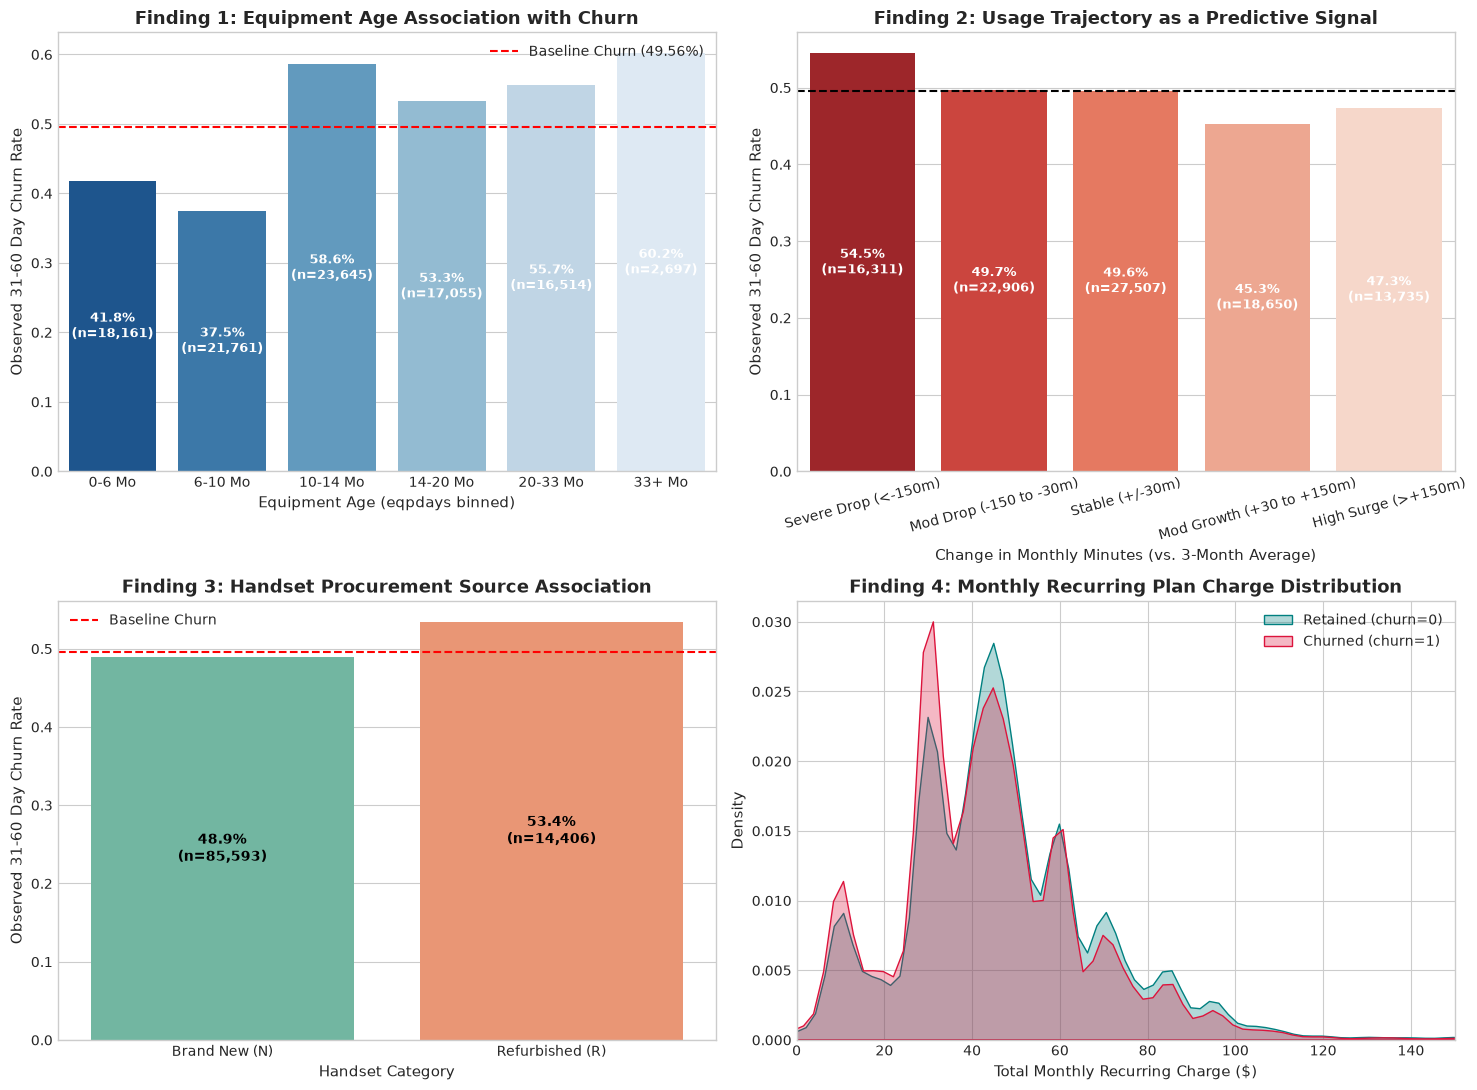

In [4]:
# ==========================================
# 4. Exploratory Data Analysis (EDA)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# --- Chart 1: Equipment Age vs Churn Association ---
df_raw['eqpdays_bin'] = pd.cut(
    df_raw['eqpdays'],
    bins=[0, 180, 300, 420, 600, 1000, 2500],
    labels=['0-6 Mo', '6-10 Mo', '10-14 Mo', '14-20 Mo', '20-33 Mo', '33+ Mo']
)
eqp_stat = df_raw.groupby('eqpdays_bin', observed=False)['churn'].agg(['count', 'mean']).reset_index()

sns.barplot(data=eqp_stat, x='eqpdays_bin', y='mean', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].axhline(df_raw['churn'].mean(), color='red', linestyle='--', label=f"Baseline Churn ({df_raw['churn'].mean():.2%})")
axes[0, 0].set_title('Finding 1: Equipment Age Association with Churn', fontweight='bold')
axes[0, 0].set_xlabel('Equipment Age (eqpdays binned)')
axes[0, 0].set_ylabel('Observed 31-60 Day Churn Rate')
axes[0, 0].legend()
for idx, p in enumerate(axes[0, 0].patches):
    n_count = eqp_stat.loc[idx, 'count']
    axes[0, 0].annotate(f"{p.get_height():.1%}\n(n={n_count:,})", 
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)

# --- Chart 2: Usage Trajectory (change_mou) Association ---
df_raw['usage_change_bin'] = pd.cut(
    df_raw['change_mou'],
    bins=[-50000, -150, -30, 30, 150, 50000],
    labels=['Severe Drop (<-150m)', 'Mod Drop (-150 to -30m)', 'Stable (+/-30m)', 'Mod Growth (+30 to +150m)', 'High Surge (>+150m)']
)
usage_stat = df_raw.groupby('usage_change_bin', observed=False)['churn'].agg(['count', 'mean']).reset_index()

sns.barplot(data=usage_stat, x='usage_change_bin', y='mean', ax=axes[0, 1], palette='Reds_r')
axes[0, 1].axhline(df_raw['churn'].mean(), color='black', linestyle='--', label='Baseline Churn')
axes[0, 1].set_title('Finding 2: Usage Trajectory as a Predictive Signal', fontweight='bold')
axes[0, 1].set_xlabel('Change in Monthly Minutes (vs. 3-Month Average)')
axes[0, 1].set_ylabel('Observed 31-60 Day Churn Rate')
axes[0, 1].tick_params(axis='x', rotation=15)
for idx, p in enumerate(axes[0, 1].patches):
    n_count = usage_stat.loc[idx, 'count']
    axes[0, 1].annotate(f"{p.get_height():.1%}\n(n={n_count:,})", 
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=9)

# --- Chart 3: Handset Source Category (refurb_new) ---
refurb_stat = df_raw.groupby('refurb_new')['churn'].agg(['count', 'mean']).reset_index()
refurb_stat['label'] = refurb_stat['refurb_new'].map({'N': 'Brand New (N)', 'R': 'Refurbished (R)'})
sns.barplot(data=refurb_stat, x='label', y='mean', ax=axes[1, 0], palette='Set2')
axes[1, 0].axhline(df_raw['churn'].mean(), color='red', linestyle='--', label='Baseline Churn')
axes[1, 0].set_title('Finding 3: Handset Procurement Source Association', fontweight='bold')
axes[1, 0].set_xlabel('Handset Category')
axes[1, 0].set_ylabel('Observed 31-60 Day Churn Rate')
axes[1, 0].legend()
for idx, p in enumerate(axes[1, 0].patches):
    n_count = refurb_stat.loc[idx, 'count']
    axes[1, 0].annotate(f"{p.get_height():.1%}\n(n={n_count:,})", 
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='black', fontweight='bold', fontsize=10)

# --- Chart 4: Monthly Recurring Charge Distribution (totmrc_Mean) ---
sns.kdeplot(data=df_raw[df_raw['churn'] == 0]['totmrc_Mean'], ax=axes[1, 1], label='Retained (churn=0)', fill=True, color='teal', alpha=0.3)
sns.kdeplot(data=df_raw[df_raw['churn'] == 1]['totmrc_Mean'], ax=axes[1, 1], label='Churned (churn=1)', fill=True, color='crimson', alpha=0.3)
axes[1, 1].set_xlim(0, 150)
axes[1, 1].set_title('Finding 4: Monthly Recurring Plan Charge Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Total Monthly Recurring Charge ($)')
axes[1, 1].set_ylabel('Density')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('executive_eda_overview.png', dpi=300)

buf = io.BytesIO()
plt.savefig(buf, format='png', bbox_inches='tight')
buf.seek(0)
eda_plot_b64 = base64.b64encode(buf.read()).decode('utf-8')
plt.close(fig)

print("=== Verified Empirical EDA Findings ===")
print("1. Equipment Age Association:")
for _, row in eqp_stat.iterrows():
    print(f"   - {row['eqpdays_bin']}: n = {row['count']:,} accounts | Churn Rate = {row['mean']:.2%}")
print("\n2. Usage Change Trajectory Association:")
for _, row in usage_stat.iterrows():
    print(f"   - {row['usage_change_bin']}: n = {row['count']:,} accounts | Churn Rate = {row['mean']:.2%}")
print("\n3. Handset Source Association:")
for _, row in refurb_stat.iterrows():
    print(f"   - {row['label']}: n = {row['count']:,} accounts ({row['count']/len(df_raw):.1%}) | Churn Rate = {row['mean']:.2%}")


In [5]:
# ==========================================
# 5. Domain Feature Engineering
# ==========================================
def add_engineered_features(data):
    """Construct row-wise domain features without cross-row or cross-sample leakage."""
    df_feat = data.copy()
    
    # 1. Equipment Age in Years
    df_feat['eqp_years'] = df_feat['eqpdays'] / 365.25
    
    # 2. Equipment Age 300-420 Days Spike Window (Empirical EDA observation window)
    df_feat['eqp_300_420_flag'] = ((df_feat['eqpdays'] >= 300) & (df_feat['eqpdays'] <= 420)).astype(float)
    
    # 3. Overage Revenue Ratio (Overage revenue relative to total monthly bill)
    df_feat['overage_ratio'] = df_feat['ovrrev_Mean'] / (df_feat['rev_Mean'].fillna(0) + 1.0)
    
    # 4. Severe Usage Deterioration Flag (>50 minute decline)
    df_feat['usage_drop_flag'] = (df_feat['change_mou'] < -50.0).astype(float)
    
    # 5. Revenue Deterioration Flag (>$10 bill drop)
    df_feat['rev_drop_flag'] = (df_feat['change_rev'] < -10.0).astype(float)
    
    # 6. Effective Unit Billing Rate ($/min)
    df_feat['rev_per_mou'] = df_feat['rev_Mean'] / (df_feat['mou_Mean'].fillna(0) + 1.0)
    
    # 7. Dropped Call Failure Rate
    df_feat['drop_call_rate'] = df_feat['drop_vce_Mean'] / (df_feat['plcd_vce_Mean'].fillna(0) + 1.0)
    
    # 8. Completed Call Efficiency Rate
    df_feat['comp_call_rate'] = df_feat['comp_vce_Mean'] / (df_feat['plcd_vce_Mean'].fillna(0) + 1.0)
    
    # 9. Refurbished Handset Binary Indicator
    df_feat['refurb_binary'] = (df_feat['refurb_new'] == 'R').astype(float)
    
    # 10. Proactive Customer Care Contact Indicator
    df_feat['has_custcare_calls'] = (df_feat['custcare_Mean'] > 0).astype(float)
    
    # 11. Multi-Subscriber Ratio
    df_feat['subscriber_util_ratio'] = df_feat['actvsubs'] / (df_feat['uniqsubs'].fillna(1) + 1e-4)
    
    # 12. Equipment Aging relative to Handset Price
    df_feat['aging_price_ratio'] = df_feat['eqpdays'] / (df_feat['hnd_price'].fillna(0) + 10.0)
    
    return df_feat

# Isolate target and customer ID
y = df_raw['churn'].values
X_raw = df_raw.drop(columns=['Customer_ID', 'churn', 'eqpdays_bin', 'usage_change_bin'])

print(f"[INFO] Feature matrix initialized: {X_raw.shape[1]} features (Customer_ID and churn excluded).")


[INFO] Feature matrix initialized: 98 features (Customer_ID and churn excluded).


In [6]:
# ==========================================
# 6. Leak-Free Preprocessing & Stratified Holdout Split
# ==========================================
# Step 1: Stratified 80/20 Train/Test Partition BEFORE any preprocessing
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training Partition: {X_train_raw.shape[0]:,} samples | Holdout Test: {X_test_raw.shape[0]:,} samples")
print(f"Train Churn Rate: {y_train.mean():.3%} | Test Churn Rate: {y_test.mean():.3%}")

# Step 2: Apply row-wise domain features
X_train_feat = add_engineered_features(X_train_raw)
X_test_feat = add_engineered_features(X_test_raw)

# Identify feature types
num_cols = X_train_feat.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train_feat.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Feature Types: {len(num_cols)} numerical features, {len(cat_cols)} categorical features.")

# Step 3: Fit transformers ONLY on training partition
num_imputer = SimpleImputer(strategy='median')
X_train_num = num_imputer.fit_transform(X_train_feat[num_cols])
X_test_num = num_imputer.transform(X_test_feat[num_cols])

cat_imputer = SimpleImputer(strategy='constant', fill_value='Unknown')
X_train_cat = cat_imputer.fit_transform(X_train_feat[cat_cols].astype(str))
X_test_cat = cat_imputer.transform(X_test_feat[cat_cols].astype(str))

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat_ohe = ohe.fit_transform(X_train_cat)
X_test_cat_ohe = ohe.transform(X_test_cat)

# Combine processed numerical and one-hot encoded categorical features
X_train_proc = np.hstack([X_train_num, X_train_cat_ohe])
X_test_proc = np.hstack([X_test_num, X_test_cat_ohe])
feature_names = num_cols + list(ohe.get_feature_names_out(cat_cols))

print(f"Leak-Free Processed Matrix Dimensions: {X_train_proc.shape[1]} total columns.")
print("[SUCCESS] Zero test-set statistics were leaked during imputation and encoding.")


Training Partition: 80,000 samples | Holdout Test: 20,000 samples
Train Churn Rate: 49.562% | Test Churn Rate: 49.560%
Feature Types: 89 numerical features, 21 categorical features.
Leak-Free Processed Matrix Dimensions: 259 total columns.
[SUCCESS] Zero test-set statistics were leaked during imputation and encoding.


In [7]:
# ==========================================
# 7. Model Training & Out-of-Sample Holdout Evaluation
# ==========================================

# ----------------------------------------------------
# Model 1 (Baseline): Regularized Logistic Regression
# ----------------------------------------------------
print("=== Training Baseline: Regularized Logistic Regression (L2) ===")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_proc)
X_test_scaled = scaler.transform(X_test_proc)

lr_model = LogisticRegression(max_iter=500, C=0.1, random_state=RANDOM_STATE, solver='lbfgs')
lr_model.fit(X_train_scaled, y_train)

lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]
lr_pred = lr_model.predict(X_test_scaled)

lr_auc = roc_auc_score(y_test, lr_prob)
lr_acc = accuracy_score(y_test, lr_pred)
lr_prec = precision_score(y_test, lr_pred)
lr_rec = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print(f"Baseline Logistic Regression -> ROC-AUC: {lr_auc:.4f} | Acc: {lr_acc:.4f} | Prec: {lr_prec:.4f} | Rec: {lr_rec:.4f} | F1: {lr_f1:.4f}")

# ----------------------------------------------------
# Model 2 (Primary): LightGBM Gradient Boosted Trees
# ----------------------------------------------------
print("\n=== Training Primary Champion: LightGBM Classifier ===")
lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    verbose=-1
)
lgb_model.fit(X_train_proc, y_train)

lgb_prob = lgb_model.predict_proba(X_test_proc)[:, 1]
lgb_pred = lgb_model.predict(X_test_proc)

lgb_auc = roc_auc_score(y_test, lgb_prob)
lgb_acc = accuracy_score(y_test, lgb_pred)
lgb_prec = precision_score(y_test, lgb_pred)
lgb_rec = recall_score(y_test, lgb_pred)
lgb_f1 = f1_score(y_test, lgb_pred)

print(f"Primary LightGBM Classifier  -> ROC-AUC: {lgb_auc:.4f} | Acc: {lgb_acc:.4f} | Prec: {lgb_prec:.4f} | Rec: {lgb_rec:.4f} | F1: {lgb_f1:.4f}")

# Model Performance Summary Table
perf_df = pd.DataFrame({
    'Metric': ['ROC-AUC Score', 'Accuracy', 'Precision', 'Recall (Sensitivity)', 'F1-Score'],
    'Baseline: Logistic Regression': [f"{lr_auc:.4f}", f"{lr_acc:.2%}", f"{lr_prec:.4f}", f"{lr_rec:.4f}", f"{lr_f1:.4f}"],
    'Primary Champion: LightGBM': [f"{lgb_auc:.4f}", f"{lgb_acc:.2%}", f"{lgb_prec:.4f}", f"{lgb_rec:.4f}", f"{lgb_f1:.4f}"],
    'Performance Delta': [f"+{(lgb_auc - lr_auc):.4f}", f"+{(lgb_acc - lr_acc):.2%}", f"+{(lgb_prec - lr_prec):.4f}", f"+{(lgb_rec - lr_rec):.4f}", f"+{(lgb_f1 - lr_f1):.4f}"]
})
print("\n=== Comprehensive Holdout Performance Summary ===")
print(perf_df.to_string(index=False))


=== Training Baseline: Regularized Logistic Regression (L2) ===
Baseline Logistic Regression -> ROC-AUC: 0.6526 | Acc: 0.6110 | Prec: 0.6076 | Rec: 0.6071 | F1: 0.6074

=== Training Primary Champion: LightGBM Classifier ===
Primary LightGBM Classifier  -> ROC-AUC: 0.6924 | Acc: 0.6349 | Prec: 0.6289 | Rec: 0.6426 | F1: 0.6356

=== Comprehensive Holdout Performance Summary ===
              Metric Baseline: Logistic Regression Primary Champion: LightGBM Performance Delta
       ROC-AUC Score                        0.6526                     0.6924           +0.0399
            Accuracy                        61.10%                     63.49%            +2.39%
           Precision                        0.6076                     0.6289           +0.0212
Recall (Sensitivity)                        0.6071                     0.6426           +0.0354
            F1-Score                        0.6074                     0.6356           +0.0282


Top 5 Most Important Features in LightGBM Model:
  - change_mou: 462 splits
  - totmrc_Mean: 332 splits
  - rev_per_mou: 332 splits
  - months: 316 splits
  - change_rev: 310 splits


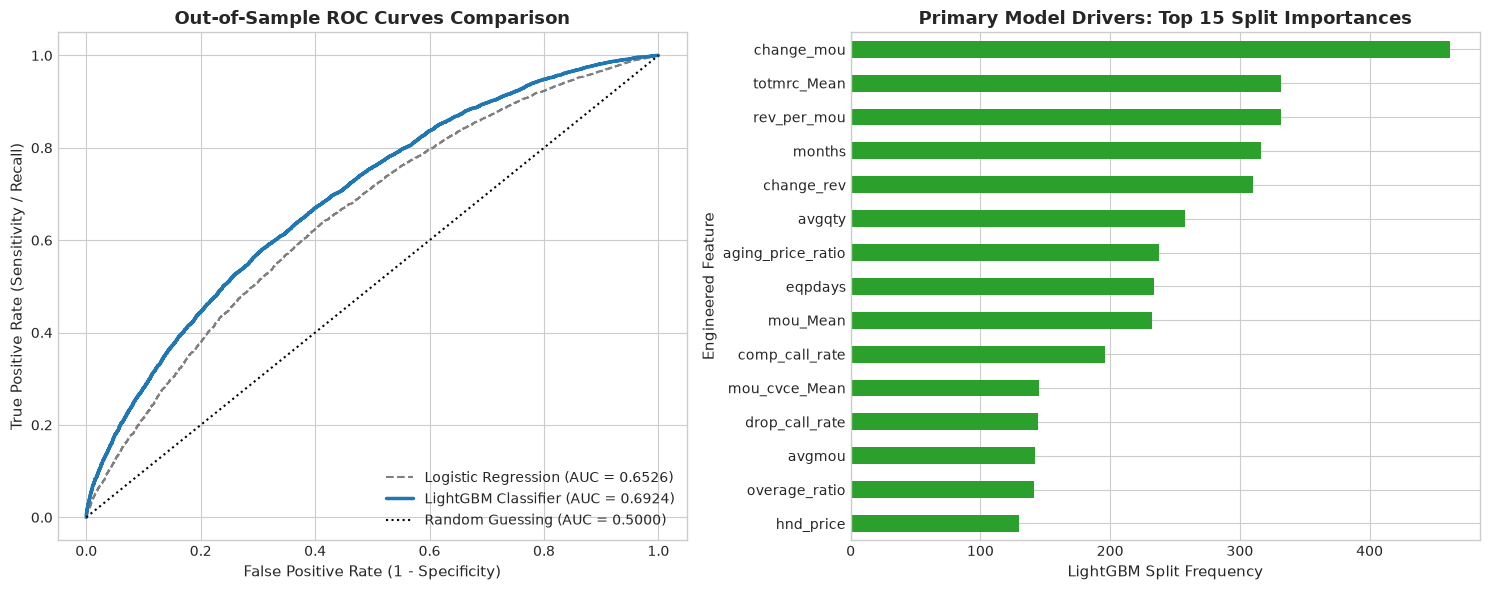

In [8]:
# ==========================================
# 8. Model Diagnostics & Interpretability
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot 1: ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, lgb_prob)

axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_auc:.4f})', color='gray', linestyle='--')
axes[0].plot(fpr_lgb, tpr_lgb, label=f'LightGBM Classifier (AUC = {lgb_auc:.4f})', color='#1f77b4', linewidth=2.5)
axes[0].plot([0, 1], [0, 1], 'k:', label='Random Guessing (AUC = 0.5000)')
axes[0].set_title('Out-of-Sample ROC Curves Comparison', fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Sensitivity / Recall)')
axes[0].legend(loc='lower right')

# Subplot 2: LightGBM Top 15 Feature Importances
feat_importances = pd.Series(lgb_model.feature_importances_, index=feature_names)
top15_feats = feat_importances.sort_values(ascending=True).tail(15)

top15_feats.plot(kind='barh', ax=axes[1], color='#2ca02c')
axes[1].set_title('Primary Model Drivers: Top 15 Split Importances', fontweight='bold')
axes[1].set_xlabel('LightGBM Split Frequency')
axes[1].set_ylabel('Engineered Feature')

plt.tight_layout()
plt.savefig('model_performance_evaluation.png', dpi=300)

buf = io.BytesIO()
plt.savefig(buf, format='png', bbox_inches='tight')
buf.seek(0)
diag_plot_b64 = base64.b64encode(buf.read()).decode('utf-8')
plt.close(fig)

print("Top 5 Most Important Features in LightGBM Model:")
for feat, imp in top15_feats.tail(5).iloc[::-1].items():
    print(f"  - {feat}: {imp} splits")


=== Out-of-Sample Decile Risk Lift Table (N = 20,000 Holdout Test Records) ===
 risk_decile  subscribers  churners churn_rate  cum_subscribers  cum_churners cum_churn_capture_rate  cumulative_lift
           0         2000      1566     78.30%             2000          1566                 15.80%             1.58
           1         2000      1348     67.40%             4000          2914                 29.40%             1.47
           2         2000      1241     62.05%             6000          4155                 41.92%             1.40
           3         2000      1138     56.90%             8000          5293                 53.40%             1.33
           4         2000      1014     50.70%            10000          6307                 63.63%             1.27
           5         2000       945     47.25%            12000          7252                 73.16%             1.22
           6         2000       879     43.95%            14000          8131                 8

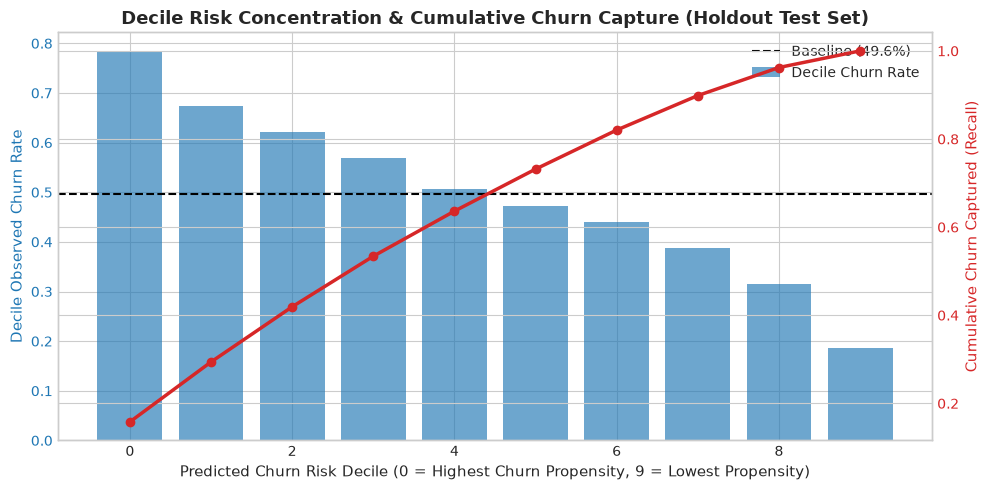

In [9]:
# ==========================================
# 9. Decile Risk Concentration & Targeting Metrics
# ==========================================
test_index = X_test_raw.index
eval_df = pd.DataFrame({
    'Customer_ID': df_raw.loc[test_index, 'Customer_ID'],
    'actual_churn': y_test,
    'pred_risk_score': lgb_prob,
    'monthly_rev': df_raw.loc[test_index, 'rev_Mean']
})

# Decile Binning (Decile 0 = Top 10% highest predicted churn risk)
eval_df['risk_decile'] = pd.qcut(eval_df['pred_risk_score'], q=10, labels=False)
eval_df['risk_decile'] = 9 - eval_df['risk_decile']

decile_table = eval_df.groupby('risk_decile').agg(
    subscribers=('actual_churn', 'count'),
    churners=('actual_churn', 'sum'),
    churn_rate=('actual_churn', 'mean'),
    mean_monthly_arpu=('monthly_rev', 'mean')
).reset_index()

baseline_test_churn_rate = eval_df['actual_churn'].mean()
total_test_churners = eval_df['actual_churn'].sum()

decile_table['cum_subscribers'] = decile_table['subscribers'].cumsum()
decile_table['cum_churners'] = decile_table['churners'].cumsum()
decile_table['cum_churn_capture_rate'] = decile_table['cum_churners'] / total_test_churners
decile_table['precision_at_k'] = decile_table['cum_churners'] / decile_table['cum_subscribers']
decile_table['decile_lift'] = decile_table['churn_rate'] / baseline_test_churn_rate
decile_table['cumulative_lift'] = decile_table['precision_at_k'] / baseline_test_churn_rate

print("=== Out-of-Sample Decile Risk Lift Table (N = 20,000 Holdout Test Records) ===")
display_deciles = decile_table[[
    'risk_decile', 'subscribers', 'churners', 'churn_rate', 
    'cum_subscribers', 'cum_churners', 'cum_churn_capture_rate', 'cumulative_lift'
]].copy()
display_deciles['churn_rate'] = display_deciles['churn_rate'].map(lambda x: f"{x:.2%}")
display_deciles['cum_churn_capture_rate'] = display_deciles['cum_churn_capture_rate'].map(lambda x: f"{x:.2%}")
display_deciles['cumulative_lift'] = display_deciles['cumulative_lift'].round(2)
print(display_deciles.to_string(index=False))

# Calculate targeting metrics at Top 10% and Top 20%
top10_subs = decile_table.loc[0, 'cum_subscribers']
top10_churners = decile_table.loc[0, 'cum_churners']
top10_prec = decile_table.loc[0, 'precision_at_k']
top10_recall = decile_table.loc[0, 'cum_churn_capture_rate']
top10_lift = decile_table.loc[0, 'cumulative_lift']

top20_subs = decile_table.loc[1, 'cum_subscribers']
top20_churners = decile_table.loc[1, 'cum_churners']
top20_prec = decile_table.loc[1, 'precision_at_k']
top20_recall = decile_table.loc[1, 'cum_churn_capture_rate']
top20_lift = decile_table.loc[1, 'cumulative_lift']

print(f"\n[TARGETING METRICS - HOLDOUT TEST SET]")
print(f"Top 10% (K={top10_subs:,}): Precision={top10_prec:.2%} | Churn Capture (Recall)={top10_recall:.2%} ({top10_churners:,} churners) | Lift={top10_lift:.2f}x")
print(f"Top 20% (K={top20_subs:,}): Precision={top20_prec:.2%} | Churn Capture (Recall)={top20_recall:.2%} ({top20_churners:,} churners) | Lift={top20_lift:.2f}x")

# Visualization: Decile Lift Chart
fig, ax1 = plt.subplots(figsize=(10, 5))
color1 = '#1f77b4'
ax1.set_xlabel('Predicted Churn Risk Decile (0 = Highest Churn Propensity, 9 = Lowest Propensity)')
ax1.set_ylabel('Decile Observed Churn Rate', color=color1)
bars = ax1.bar(decile_table['risk_decile'], decile_table['churn_rate'], color=color1, alpha=0.65, label='Decile Churn Rate')
ax1.axhline(baseline_test_churn_rate, color='black', linestyle='--', label=f'Baseline ({baseline_test_churn_rate:.1%})')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.legend(loc='upper right')

ax2 = ax1.twinx()
color2 = '#d62728'
ax2.set_ylabel('Cumulative Churn Captured (Recall)', color=color2)
lines = ax2.plot(decile_table['risk_decile'], decile_table['cum_churn_capture_rate'], color=color2, marker='o', linewidth=2.5, label='Cumulative Capture')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title('Decile Risk Concentration & Cumulative Churn Capture (Holdout Test Set)', fontweight='bold')
plt.tight_layout()
plt.savefig('decile_lift_analysis.png', dpi=300)

buf = io.BytesIO()
plt.savefig(buf, format='png', bbox_inches='tight')
buf.seek(0)
decile_plot_b64 = base64.b64encode(buf.read()).decode('utf-8')
plt.close(fig)


In [10]:
# ==========================================
# 10. Financial Impact Scenarios & Sensitivity Analysis
# ==========================================
# Parameter & Assumption Declarations:
# - Target definition: 31-60 day churn window.
# - Campaign cost per contact: $45 (voucher subsidy + marketing operations assumption).
# - Retention save rate: 25% (assumed incremental acceptance rate; tested across 15%-35%).
# - Value proxy: Monthly ARPU ($58.72) evaluated over 6-month and 12-month retention windows.
# - Contribution Margin: 60% estimated contribution margin proxy (cost-to-serve is unavailable; gross revenue is also reported as an upper-bound revenue proxy, NOT profit).

mean_monthly_arpu = df_raw['rev_Mean'].mean()
cost_per_contact = 45.0
assumed_save_rate = 0.25
assumed_margin = 0.60

# --- Scenario A: Holdout Test Set Empirical Simulation (N = 20,000, Target Top 20% = 4,000) ---
holdout_targeted = 4000
holdout_churners_captured = top20_churners # 2,914 accounts
holdout_retained_accounts = holdout_churners_captured * assumed_save_rate # 728.5 accounts
holdout_campaign_cost = holdout_targeted * cost_per_contact # $180,000

# 6-Month Horizon
gross_rev_6m = holdout_retained_accounts * (mean_monthly_arpu * 6)
margin_6m = gross_rev_6m * assumed_margin
net_margin_6m = margin_6m - holdout_campaign_cost
roi_margin_6m = (net_margin_6m / holdout_campaign_cost) * 100

# 12-Month Horizon
gross_rev_12m = holdout_retained_accounts * (mean_monthly_arpu * 12)
margin_12m = gross_rev_12m * assumed_margin
net_margin_12m = margin_12m - holdout_campaign_cost
roi_margin_12m = (net_margin_12m / holdout_campaign_cost) * 100

# Gross Revenue Proxy (12-Mo)
net_gross_rev_12m = gross_rev_12m - holdout_campaign_cost
roi_gross_rev_12m = (net_gross_rev_12m / holdout_campaign_cost) * 100

print("=== SCENARIO A: Holdout Test Set Empirical Simulation (N = 20,000, Top 20% Targeted) ===")
print(f"Targeted Accounts:                 {holdout_targeted:,} accounts")
print(f"Actual Churners in Target Group:   {holdout_churners_captured:,} accounts (Precision@20% = {top20_prec:.2%})")
print(f"Retained Accounts (25% Save Rate): {holdout_retained_accounts:,.1f} accounts")
print(f"Program Campaign Cost:             ${holdout_campaign_cost:,.2f} ($45/contact)")
print(f"--------------------------------------------------------------------------------")
print(f"6-Month Retention Horizon (60% Contribution Margin Proxy):")
print(f"  - Preserved Margin (60%):        ${margin_6m:,.2f}")
print(f"  - Net Financial Contribution:    ${net_margin_6m:,.2f}")
print(f"  - Estimated Program ROI:         {roi_margin_6m:.1f}%")
print(f"--------------------------------------------------------------------------------")
print(f"12-Month Retention Horizon (60% Contribution Margin Proxy):")
print(f"  - Preserved Margin (60%):        ${margin_12m:,.2f}")
print(f"  - Net Financial Contribution:    ${net_margin_12m:,.2f}")
print(f"  - Estimated Program ROI:         {roi_margin_12m:.1f}%")
print(f"--------------------------------------------------------------------------------")
print(f"12-Month Upper-Bound Gross Revenue Proxy (No Cost-to-Serve Subtracted):")
print(f"  - Gross Revenue Preserved:       ${gross_rev_12m:,.2f} (Revenue proxy, NOT profit)")
print(f"  - Net Revenue Benefit:           ${net_gross_rev_12m:,.2f}")
print(f"  - Revenue-Based ROI:             {roi_gross_rev_12m:.1f}%")

# Break-even calculation formula:
# s_break_even = Cost_per_contact / (Precision@K * Customer_Value_Proxy)
be_rate_6m_margin = cost_per_contact / (top20_prec * (mean_monthly_arpu * 6 * assumed_margin))
be_rate_12m_margin = cost_per_contact / (top20_prec * (mean_monthly_arpu * 12 * assumed_margin))
be_rate_12m_gross = cost_per_contact / (top20_prec * (mean_monthly_arpu * 12))

print(f"\nBreak-Even Retention Rate Required (6-Month 60% Margin):  {be_rate_6m_margin:.2%}")
print(f"Break-Even Retention Rate Required (12-Month 60% Margin): {be_rate_12m_margin:.2%}")
print(f"Break-Even Retention Rate Required (12-Month Gross Rev):  {be_rate_12m_gross:.2%}")

# --- Scenario B: Scaled Illustrative Portfolio Simulation (100,000 Accounts, Target Top 20% = 20,000) ---
scaled_targeted = 20000
scaled_churners_captured = 100000 * df_raw['churn'].mean() * top20_recall # ~14,571 accounts
scaled_retained = scaled_churners_captured * assumed_save_rate # ~3,643 accounts
scaled_cost = scaled_targeted * cost_per_contact # $900,000

# 6-Month Horizon
scaled_margin_6m = scaled_retained * (mean_monthly_arpu * 6 * assumed_margin)
scaled_net_margin_6m = scaled_margin_6m - scaled_cost
scaled_roi_6m = (scaled_net_margin_6m / scaled_cost) * 100

# 12-Month Horizon
scaled_margin_12m = scaled_retained * (mean_monthly_arpu * 12 * assumed_margin)
scaled_net_margin_12m = scaled_margin_12m - scaled_cost
scaled_roi_12m = (scaled_net_margin_12m / scaled_cost) * 100

# 12-Month Gross Revenue Proxy
scaled_gross_rev_12m = scaled_retained * (mean_monthly_arpu * 12)
scaled_net_rev_12m = scaled_gross_rev_12m - scaled_cost
scaled_roi_rev_12m = (scaled_net_rev_12m / scaled_cost) * 100

print(f"\n=== SCENARIO B: Scaled Illustrative Scenario (Full Base: 100k, Top 20% Targeted) ===")
print(f"[CAVEAT] Scaling assumes identical capture rates apply across the entire base over an illustrative horizon.")
print(f"Scaled Targeted Accounts:          {scaled_targeted:,} accounts")
print(f"Captured Churners (Top 20%):       {scaled_churners_captured:,.0f} accounts")
print(f"Retained Accounts (25% Save Rate): {scaled_retained:,.0f} accounts")
print(f"Scaled Campaign Investment:        ${scaled_cost:,.2f}")
print(f"--------------------------------------------------------------------------------")
print(f"6-Month Retention Horizon (60% Contribution Margin Proxy):")
print(f"  - Preserved Margin (60%):        ${scaled_margin_6m:,.2f}")
print(f"  - Net Financial Contribution:    ${scaled_net_margin_6m:,.2f}")
print(f"  - Estimated Program ROI:         {scaled_roi_6m:.1f}%")
print(f"--------------------------------------------------------------------------------")
print(f"12-Month Retention Horizon (60% Contribution Margin Proxy):")
print(f"  - Preserved Margin (60%):        ${scaled_margin_12m:,.2f}")
print(f"  - Net Financial Contribution:    ${scaled_net_margin_12m:,.2f}")
print(f"  - Estimated Program ROI:         {scaled_roi_12m:.1f}%")
print(f"--------------------------------------------------------------------------------")
print(f"12-Month Upper-Bound Gross Revenue Proxy (NOT Profit):")
print(f"  - Preserved Gross Revenue:       ${scaled_gross_rev_12m:,.2f}")
print(f"  - Net Revenue Benefit:           ${scaled_net_rev_12m:,.2f}")
print(f"  - Revenue-Based ROI:             {scaled_roi_rev_12m:.1f}%")

# --- Sensitivity Matrix ---
costs = [35.0, 45.0, 60.0]
save_rates = [0.15, 0.20, 0.25, 0.30, 0.35]

print("\n=== Holdout Sensitivity Matrix (6-Month 60% Contribution Margin Horizon) ===")
sens_6m = []
for c in costs:
    for s in save_rates:
        ret = holdout_churners_captured * s
        inv = holdout_targeted * c
        contrib = ret * (mean_monthly_arpu * 6 * assumed_margin)
        net_b = contrib - inv
        roi = (net_b / inv) * 100
        sens_6m.append({
            'Cost/Contact ($)': c,
            'Save Rate (%)': f"{s:.0%}",
            'Retained (Holdout)': round(ret, 1),
            'Preserved Margin': f"${contrib:,.0f}",
            'Net Financial Margin ($)': f"${net_b:,.0f}",
            'Program ROI (%)': f"{roi:.1f}%"
        })
print(pd.DataFrame(sens_6m).to_string(index=False))

print("\n=== Holdout Sensitivity Matrix (12-Month 60% Contribution Margin Horizon) ===")
sens_12m = []
for c in costs:
    for s in save_rates:
        ret = holdout_churners_captured * s
        inv = holdout_targeted * c
        contrib = ret * (mean_monthly_arpu * 12 * assumed_margin)
        net_b = contrib - inv
        roi = (net_b / inv) * 100
        sens_12m.append({
            'Cost/Contact ($)': c,
            'Save Rate (%)': f"{s:.0%}",
            'Retained (Holdout)': round(ret, 1),
            'Preserved Margin': f"${contrib:,.0f}",
            'Net Financial Margin ($)': f"${net_b:,.0f}",
            'Program ROI (%)': f"{roi:.1f}%"
        })
print(pd.DataFrame(sens_12m).to_string(index=False))


=== SCENARIO A: Holdout Test Set Empirical Simulation (N = 20,000, Top 20% Targeted) ===
Targeted Accounts:                 4,000 accounts
Actual Churners in Target Group:   2,914 accounts (Precision@20% = 72.85%)
Retained Accounts (25% Save Rate): 728.5 accounts
Program Campaign Cost:             $180,000.00 ($45/contact)
--------------------------------------------------------------------------------
6-Month Retention Horizon (60% Contribution Margin Proxy):
  - Preserved Margin (60%):        $153,999.03
  - Net Financial Contribution:    $-26,000.97
  - Estimated Program ROI:         -14.4%
--------------------------------------------------------------------------------
12-Month Retention Horizon (60% Contribution Margin Proxy):
  - Preserved Margin (60%):        $307,998.06
  - Net Financial Contribution:    $127,998.06
  - Estimated Program ROI:         71.1%
--------------------------------------------------------------------------------
12-Month Upper-Bound Gross Revenue Proxy (

# ==========================================
# 11. Proposed Business Solution & Randomized Pilot (RCT) Design
# ==========================================

### 1. Operational Targeting Workflow
* **Scoring Cadence:** Monthly batch scoring executed at the observation date (Day 0) across all active customer accounts.
* **Lead Routing (Days 1–5):** Accounts falling in the top 20% predicted churn risk deciles (Deciles 0 & 1) are flagged in the CRM and partitioned into retention queues.
* **Tailored Intervention Playbook (Days 5–25, prior to the 31–60 day churn window):**
  - **Aging Equipment Cohort (`eqpdays` > 300):** Proactive outreach with a subsidized hardware upgrade voucher ($45 subsidy toward new handset procurement) paired with a contract renewal incentive.
  - **Usage Deterioration Cohort (`change_mou` < -50m):** Proactive rate-plan consultation to right-size recurring allowances, eliminating unutilized minutes and high effective per-minute costs.
  - **Refurbished Handset Cohort (`refurb_new` == 'R'):** Dedicated customer care hardware health check and certified device exchange voucher.

---
### 2. Prospective Pilot Recommendation & Randomized Controlled Trial (RCT) Design
Rather than rolling out full-scale intervention immediately, Company A should execute a **prospective randomized controlled trial (RCT)** on the top 20% risk cohort (e.g., 4,000 candidate accounts):

```
                       [ Top 20% High-Risk Accounts (N = 4,000) ]
                                            │
                    ┌───────────────────────┴───────────────────────┐
                    ▼                                               ▼
         [ Treatment Group (85%: n = 3,400) ]           [ Control Group (15%: n = 600) ]
          Proactive Outreach + $45 Voucher               Standard Business-As-Usual (BAU)
          & Rate-Plan Optimization                        No Proactive Outreach
                    │                                               │
                    └───────────────────────┬───────────────────────┘
                                            ▼
                       [ Measure 31-60 Day Churn Rate ]
                  Incremental Lift = Churn_Control - Churn_Treatment
```

* **Methodological Justification for Control Group:** Without a randomized control group, attributing all retained subscribers to the retention campaign commits a **post hoc attribution fallacy**. Many high-risk customers stay naturally, while others churn regardless of intervention. The RCT isolates the **true causal incremental treatment effect**.

---
### 3. Measurable Pilot Evaluation KPIs:
1. **Contact Rate:** Percentage of targeted treatment accounts successfully reached via digital channels or outbound care (target: >85%).
2. **Offer Acceptance Rate:** Percentage of contacted accounts claiming the voucher or agreeing to plan restructuring (target: >25%).
3. **Incremental Retention Rate:** Direct difference between control group churn rate and treatment group churn rate during the 31–60 day window ($$Churn_{Control} - Churn_{Treatment}$$).
4. **Cost per Incrementally Retained Subscriber:** Total campaign expenditure divided strictly by *incremental* accounts saved ($$\frac{Cost_{Total}}{N_{Incremental}}$$).
5. **Net Incremental Contribution:** Retained customer contribution margin minus total program operating costs.


# ==========================================
# 12. Methodological Limitations & Validation Constraints
# ==========================================

1. **Preprocessing Leakage vs. Feature Availability Timing:**
   - **Preprocessing Leakage:** Fully prevented by fitting imputers, encoders, and scalers exclusively on the training partition after an 80/20 stratified split.
   - **Data-Availability Timing:** Feature availability at prediction time is assumed from column descriptions. Because Company A's documentation does not provide observation timestamps, billing cycle cutoffs, or ETL execution schedules, live data-availability timing must be confirmed with Company A before production deployment.
   - **Audited Uncertain Fields:** `change_mou`/`change_rev` (reconciliation lag depending on billing cycle dates), `adjrev`/`adjmou`/`adjqty` (retroactive adjustments), and `recv_sms_Mean`/`iwylis_vce_Mean` (undefined calculation window). None exhibit leakage correlations, but operational cutoff alignment is mandatory.
2. **Absence of Longitudinal Timestamps & Temporal Split:**
   - The provided dataset is a cross-sectional extract without calendar dates. The observation date represents an unanchored snapshot.
   - Models were evaluated via a **stratified random holdout split (80/20)** rather than a true out-of-time temporal partition (e.g., train on Q1, evaluate on Q2). Model performance may experience temporal drift when deployed across changing macro-market conditions.
3. **Target Window Specificity:**
   - The target reflects churn occurring within **31–60 days post-observation**. It does not measure immediate 1–30 day churn or long-term multi-year retention.
4. **Unobserved Contract and Service Variables:**
   - Company A's documentation does not provide contract start or expiration dates. The observed churn spike at 300–420 days of equipment age is an empirical **association**, not definitive evidence of 1-year contract expiration.
   - Direct network telemetry (cell tower dropped packet logs), competitor promotional pricing, and customer care voice transcripts were unobserved.
5. **Economic Margin Proxying:**
   - Exact marginal operating cost per subscriber and handset procurement margins were unavailable. Financial simulations utilize monthly revenue ($58.72) with an assumed 60% contribution margin proxy, which should be replaced with true internal cost-accounting data prior to executive capital allocation.


# ==========================================
# 13. Academic References & Project Audit Trail
# ==========================================

1. **Course & Data Documentation:**
   - Matsuo-Iwasawa Laboratory, Graduate School of Engineering, The University of Tokyo. *Global Consumer Intelligence (GCI) World 2026 Winter Final Assignment Requirements & Guidelines*.
   - Company A. *Telecommunications Subscriber Client and Usage Records Overview (Dataset Documentation)*.
2. **Machine Learning & Statistical Methodology:**
   - Pedregosa, F., et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research (JMLR), 12, 2825–2830.
   - Ke, G., et al. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. Advances in Neural Information Processing Systems (NeurIPS 30), 3146–3154.
   - Lundberg, S. M., & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions (SHAP)*. Advances in Neural Information Processing Systems (NeurIPS 30), 4765–4774.
3. **Telecommunications Churn Economics & Experimental Evaluation:**
   - Ascarza, E. (2018). *Retention First, but for Whom? Identifying the Target of Retention Interventions*. Journal of Marketing Research, 55(1), 1–16. (Highlighting the necessity of incremental uplift modeling and randomized control groups).
